# 实验7：图像的腐蚀和膨胀

本实验的图片、代码和操作步骤均已包含在本文件夹中。

**运行方式：** 选择本项目的 `.venv` 内核，依次执行单元格，或点击“全部运行”。重新开始时先重启内核。

## 实验目的

观察灰度腐蚀与膨胀，明确白色前景约定，比较不同结构元素与处理次数。

## 实验原理

灰度腐蚀取结构元素覆盖区域的局部最小值，膨胀取局部最大值；它们不是普通的线性卷积。二值图以白色为前景时，腐蚀使白色区域缩小，膨胀使其扩大。先观察电路板灰度图的变化，再观察白色二值零件的变化。


## 1. 准备环境与路径

算法使用 OpenCV；显示使用 Matplotlib。彩色数组按 BGR 存储，显示前转换成 RGB。图中标题采用英文，说明和练习采用中文，减少系统字体差异。


In [1]:
from pathlib import Path
import sys

# 从 lab 根目录或任意实验子目录启动均可。
HERE = Path.cwd().resolve()
ROOT = next((p for p in (HERE, *HERE.parents)
             if (p / "assets" / "manifest.json").is_file()
             and (p / "common" / "io.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("请在 lab 文件夹或其子目录中启动 Notebook。")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import cv2
import numpy as np
import matplotlib.pyplot as plt
from common.io import read_image, save_image, show_images

ASSETS = ROOT / "assets"
OUT = ROOT / "outputs" / "lab07"
OUT.mkdir(parents=True, exist_ok=True)


## 2. 电路板的灰度形态学

先把电路板照片转换成灰度图，再进行腐蚀和膨胀。暗色芯片会在灰度腐蚀中扩大，因为周围像素被较小值替代。


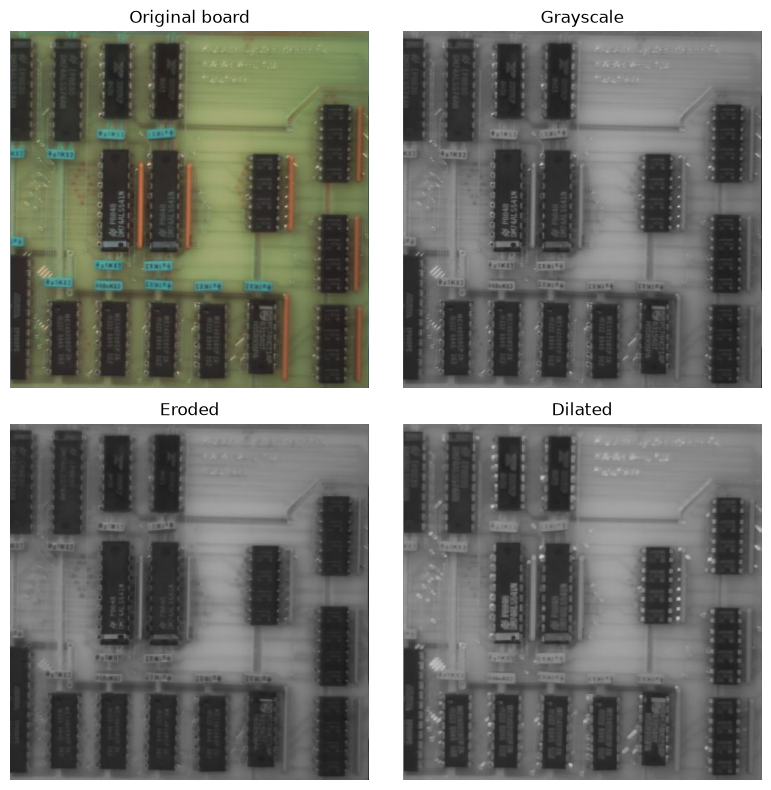

PosixPath('/Users/yiqing/Documents/ChatGPT/机器学习授课/lab/outputs/lab07/board_dilated.png')

In [2]:
board = read_image(ASSETS / "pdf/circuit_board.png")
gray = cv2.cvtColor(board, cv2.COLOR_BGR2GRAY)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
eroded = cv2.erode(gray, kernel, iterations=1)
dilated = cv2.dilate(gray, kernel, iterations=1)
show_images({"Original board": board, "Grayscale": gray, "Eroded": eroded, "Dilated": dilated},
            cols=2, save_to=OUT / "board_morphology.png")
save_image(OUT / "board_eroded.png", eroded)
save_image(OUT / "board_dilated.png", dilated)


## 3. 零件二值化：统一为白色前景

零件原图较暗，因此采用反二值化 + Otsu，让零件为白、背景为黑。此时才能用白色面积清楚说明“缩小/扩大”。


Otsu 阈值: 97.0 白色面积 [腐蚀, 原始, 膨胀]: [88813, 100715, 111569]


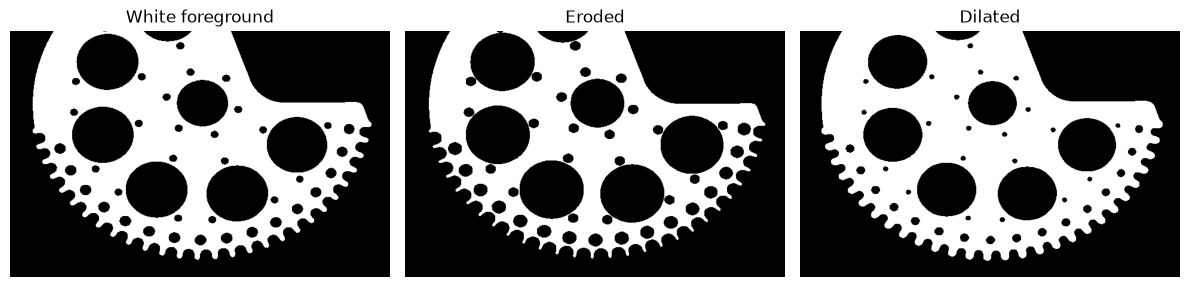

PosixPath('/Users/yiqing/Documents/ChatGPT/机器学习授课/lab/outputs/lab07/part_binary.png')

In [3]:
part = read_image(ASSETS / "pdf/mechanical_part.png", gray=True)
otsu_value, binary = cv2.threshold(part, 0, 255, cv2.THRESH_BINARY_INV | cv2.THRESH_OTSU)
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
e = cv2.erode(binary, kernel, iterations=1)
d = cv2.dilate(binary, kernel, iterations=1)
areas = [int(np.count_nonzero(a)) for a in (e, binary, d)]
assert areas[0] <= areas[1] <= areas[2]
print("Otsu 阈值:", otsu_value, "白色面积 [腐蚀, 原始, 膨胀]:", areas)
show_images({"White foreground": binary, "Eroded": e, "Dilated": d}, cols=3,
            save_to=OUT / "binary_morphology.png")
save_image(OUT / "part_binary.png", binary)


## 4. 核大小、形状和迭代次数

先固定结构元素，比较处理次数。扩展观察：开运算先腐蚀再膨胀，闭运算先膨胀再腐蚀。


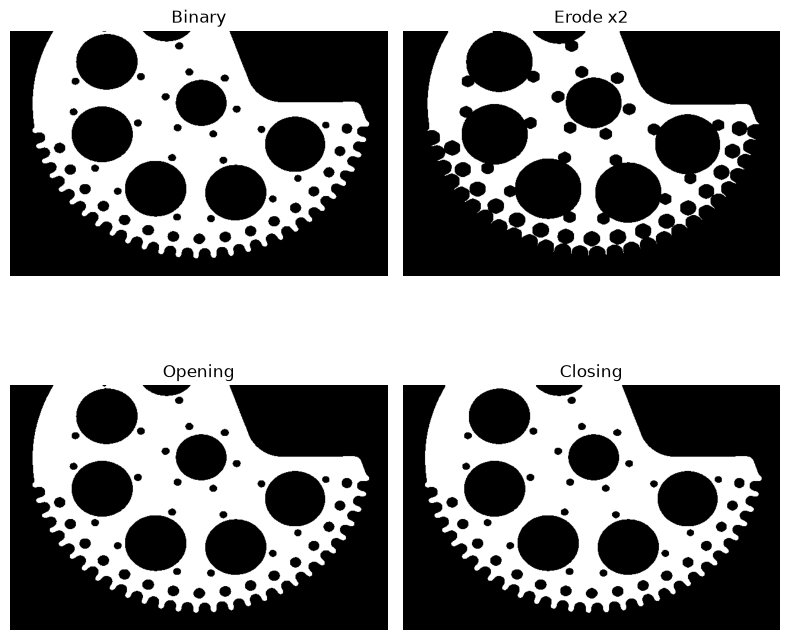

PosixPath('/Users/yiqing/Documents/ChatGPT/机器学习授课/lab/outputs/lab07/part_closed.png')

In [4]:
iterations = 2  # 练习：改为 1 或 3
kernel_size = 5  # 练习：改为 3 或 9，保持正奇数
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kernel_size, kernel_size))
eroded_n = cv2.erode(binary, kernel, iterations=iterations)
opened = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
closed = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)
show_images({"Binary": binary, f"Erode x{iterations}": eroded_n, "Opening": opened, "Closing": closed}, cols=2)
save_image(OUT / "part_opened.png", opened)
save_image(OUT / "part_closed.png", closed)


## 记录与思考

1. 为什么灰度电路板腐蚀后暗色芯片看起来更大，而白色二值零件变小？
2. 增大结构元素会损失哪些细节？
3. 比较矩形核、椭圆核和十字核。
4. 可选：读取熊猫灰度图并做腐蚀、膨胀，解释其局限。

### 我的实验记录

- 使用的素材：
- 修改的参数：
- 观察到的现象：
- 结论与原因：

> 图像和图表保存到 `outputs/lab07/`；运行本 Notebook 不会改写原始素材。
